In [2]:
from ssh_chain_sq import (PHOTONICChain, min_pairwise_gap, sweep_discriminability)
import thesis_cmaps                    # registers the "thesis_cmap" colormaps
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import scienceplots
plt.style.use(['science', 'no-latex', 'notebook'])

# chi is dimensionless (qubit frequency = 1). The swept discriminability metric
# is divided by g_const**2 (chi ~ O(g^2 kerr)); CHI_UNIT = 1e-3 (the "MHz vs
# GHz" scale) is only used for the validation printouts.
CHI_UNIT = 1e-3
CMAP     = 'thesis_cmap'


def log_heatmap(ax, x, y, Z, label='', cmap=CMAP, norm=None, contours=True):
    '''pcolormesh of Z on a LogNorm colour scale whose ticks read the actual
    value (not log10), plus optional log-spaced contour lines. Non-positive /
    non-finite entries (outside the dispersive regime) are left blank.'''
    Zp = np.where(np.isfinite(Z) & (Z > 0), Z, np.nan)
    finite = Zp[np.isfinite(Zp)]
    if finite.size == 0:
        ax.text(0.5, 0.5, 'no dispersive points', ha='center', va='center',
                transform=ax.transAxes, fontsize=8)
        return None
    if norm is None:
        vmin, vmax = finite.min(), finite.max()
        if vmin == vmax:
            vmin, vmax = vmin / 10, vmax * 10
        norm = LogNorm(vmin=vmin, vmax=vmax)
    im = ax.pcolormesh(x, y, Zp, cmap=cmap, shading='nearest', norm=norm)
    if label:
        ax.figure.colorbar(im, ax=ax, label=label)
    if contours:
        lo, hi = np.floor(np.log10(norm.vmin)), np.ceil(np.log10(norm.vmax))
        lv = np.logspace(lo, hi, int(hi - lo) + 1)
        lv = lv[(lv > norm.vmin) & (lv < norm.vmax)]
        if len(lv):
            cs = ax.contour(x, y, Zp, levels=lv, colors='w', linewidths=0.5)
            ax.clabel(cs, inline=True, fontsize=6, fmt=lambda v: f'{v:g}')
    return im

In [3]:
N        = 3
Omega_J  = 1.0
Chi_J    = 0.0
kerr     = 0.05
gamma    = 0.0
omega_r  = 1.0            # original cavity -- decoupled here (gamma = 0)
g_const  = 1.0e-3        # uniform per-site probe coupling -- small, so nearly every
                         # (Omega_C, Chi_C) point stays dispersive and the g^2-
                         # normalized metric sits at its g -> 0 limit
NORM     = g_const ** 2  # chi ~ O(g^2 kerr): divide by this for a g-independent metric

def make_chain(Omega_C, Chi_C, pbc=False):
    return PHOTONICChain(N=N, Omega_C=Omega_C, Chi_C=Chi_C, omega_r=omega_r,
                         gamma=gamma, fock_photon=1, Omega_J=Omega_J,
                         Chi_J=Chi_J, kerr=kerr, PBC=pbc)

chain   = make_chain(0.6, 0.35)
n       = chain.n
g_sites = np.full(n, g_const)
print('eta-mode frequencies:', np.round(2.0 * np.diag(chain.H_C)[:n].real, 4))

eta-mode frequencies: [0.6638 0.7522 0.8448 1.1288 1.1927 1.2436]


In [4]:
GRID           = 40
omega_C_values = np.linspace(0.1, 0.8, GRID)
chi_C_neg      = np.linspace(-0.8, -0.1, GRID)
chi_C_pos      = np.linspace( 0.1,  0.8, GRID)

def run_bands(gap_index, pbc=False, label='', g=g_const):
    '''min|d chi| / g^2 over the (Omega_C, Chi_C) grid for chi_C<0 and chi_C>0,
    probe adaptively placed in gap `gap_index` at every grid point.'''
    kw = dict(g_sites=np.full(n, g), gap_index=gap_index, normalize=g ** 2,
              dispersive_tol=0.3, degeneracy_tol=1e-6)
    mk = lambda oc, cc: make_chain(oc, cc, pbc)
    return dict(label=label, gap_index=gap_index, g=g,
                neg=sweep_discriminability(mk, omega_C_values, chi_C_neg, **kw),
                pos=sweep_discriminability(mk, omega_C_values, chi_C_pos, **kw))

def report_best(res):
    for sgn, cv in [('neg', chi_C_neg), ('pos', chi_C_pos)]:
        G = res[sgn]['gap_grid']
        if not np.isfinite(G).any():
            print(f"  {sgn}: no dispersive points"); continue
        b   = np.unravel_index(np.nanargmax(G), G.shape)
        chi = res[sgn]['chi_cube'][b]
        wr  = res[sgn]['omega_r_new_grid'][b]
        print(f"  {sgn}: best min|d chi|/g^2 = {G[b]:.3g} [1/w_q] at Omega_C="
              f"{omega_C_values[b[1]]:.3f}, Chi_C={cv[b[0]]:.3f} "
              f"(omega_r_new={wr:.3f})")
        print(f"        chi/g^2 = {np.round(chi / res['g'] ** 2, 4)}")
    return res

  neg: best min|d chi|/g^2 = 2.05e-10 [1/w_q] at Omega_C=0.190, Chi_C=-0.746 (omega_r_new=1.082)
        chi/g^2 = [-2291.8657 -2289.4001 -2289.4001 -2302.7414 -2302.7414 -2149.0483]
  pos: best min|d chi|/g^2 = 1.23e-10 [1/w_q] at Omega_C=0.154, Chi_C=0.656 (omega_r_new=1.065)
        chi/g^2 = [-2000.8885 -1999.2904 -1999.2904 -2006.8526 -2006.8526 -1889.8256]


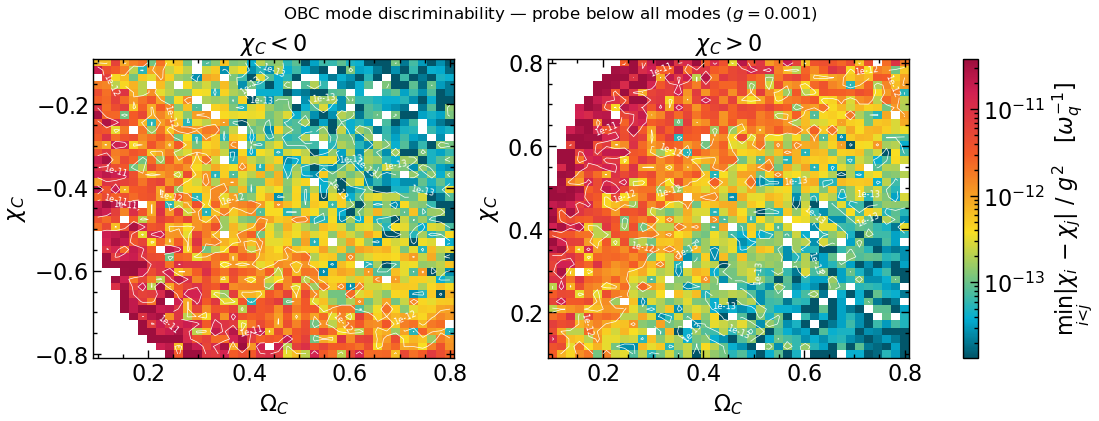

In [10]:
# probe below all modes (gap_index = -1): the two sign regions, side by side
below = report_best(run_bands(4, pbc=True, label='below all'))

gn = below['neg']['gap_grid']; gp = below['pos']['gap_grid']
allv = np.concatenate([gn[np.isfinite(gn)], gp[np.isfinite(gp)]]); allv = allv[allv > 0]
norm = LogNorm(*np.percentile(allv, [2, 98]))          # robust to near-resonant outliers

METRIC_LABEL = r'$\min_{i<j}|\chi_i-\chi_j|\ /\ g^2\quad[\omega_q^{-1}]$'

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
last = None
for ax, cv, G, ttl in [(axes[0], chi_C_neg, gn, r'$\chi_C<0$'),
                       (axes[1], chi_C_pos, gp, r'$\chi_C>0$')]:
    im = log_heatmap(ax, omega_C_values, cv, G, norm=norm)
    last = im or last
    ax.set_xlabel(r'$\Omega_C$'); ax.set_ylabel(r'$\chi_C$'); ax.set_title(ttl)
fig.colorbar(last, ax=list(axes), label=METRIC_LABEL)
fig.suptitle(rf'OBC mode discriminability — probe below all modes ($g={g_const:g}$)')
plt.show()